In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import plot_tree
from sklearn.model_selection import RandomizedSearchCV

In [2]:
df = pd.read_csv(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Data/Processed/cleaned_dataset.csv")
df.head()
df = df.drop(columns=["LULC"])

In [3]:
# One hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["LULC_Name"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["LULC_Name"]),
    index = df.index
)

df = pd.concat([df.drop(columns=["LULC_Name"]),encoded_df], axis=1)

In [4]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope',
       'WindSpeed', 'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='str')

In [5]:
X = df.drop(columns=["LST"])
y = df["LST"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [7]:
rf = RandomForestRegressor(
    random_state=43,
    oob_score=True
)

rf.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.r2_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",43
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node s

In [8]:
y_pred_train = rf.predict(X_train)
y_pred_test = rf.predict(X_test)

print(f"oob_score of data = {rf.oob_score_}")

print(f"MSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

oob_score of data = 0.8329083299244289
MSE of training data = 0.5176235218727311
MSE of testing data = 1.3565593471031374
r2_score of training data = 0.9768482258352877
r2_score of testing data = 0.836595184473834


# Hyperparameter tuning to reduce overfitting

In [9]:
# param_grid = {
#     "n_estimators" : [100,200,300,400,500],
#     "max_depth" : [10,15,20,25,30],
#     "min_samples_split" : [5,10,15,20,25],
#     "min_samples_leaf" : [1,2,3,4,5]
# }

# random_search = RandomizedSearchCV(
#     rf,
#     param_grid,
#     scoring="r2",
#     n_iter=30,
#     cv=5,
#     n_jobs=-1
# )

# random_search.fit(X_train, y_train)
# best_r2_score = random_search.best_score_
# best_param = random_search.best_params_

In [10]:
# print(best_r2_score)
# print(best_param)

In [11]:
rf2 = RandomForestRegressor(
    random_state=43,
    oob_score=True,
    n_estimators=300,
    min_samples_split=10,
    min_samples_leaf=3,
    max_depth=15
)

rf2.fit(X_train, y_train)

y_pred_train = rf2.predict(X_train)
y_pred_test = rf2.predict(X_test)

print(f"oob_score of data = {rf2.oob_score_}")

print(f"MSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")
print(f"mean absolute error of testing data = {mean_absolute_error(y_test, y_pred_test)}")

oob_score of data = 0.8320123849483563
MSE of training data = 0.881743663242594
MSE of testing data = 1.3550599076368348
r2_score of training data = 0.9328198506113525
r2_score of testing data = 0.8369562158122871
mean absolute error of testing data = 1.0287837619265523


In [12]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf2.feature_importances_*100
})

importance = importance.sort_values(by="Importance", ascending=False)

importance

,Feature,Importance
7,NDBI,64.273765
1,Longitude,15.276305
0,Latitude,4.204940
3,DistanceToWater,3.550056
9,Population,3.507491
6,MNDWI,3.149544
8,NDVI,1.811827
4,Elevation,1.277117
10,Slope,0.997295
12,LULC_Name_Built Area,0.569154


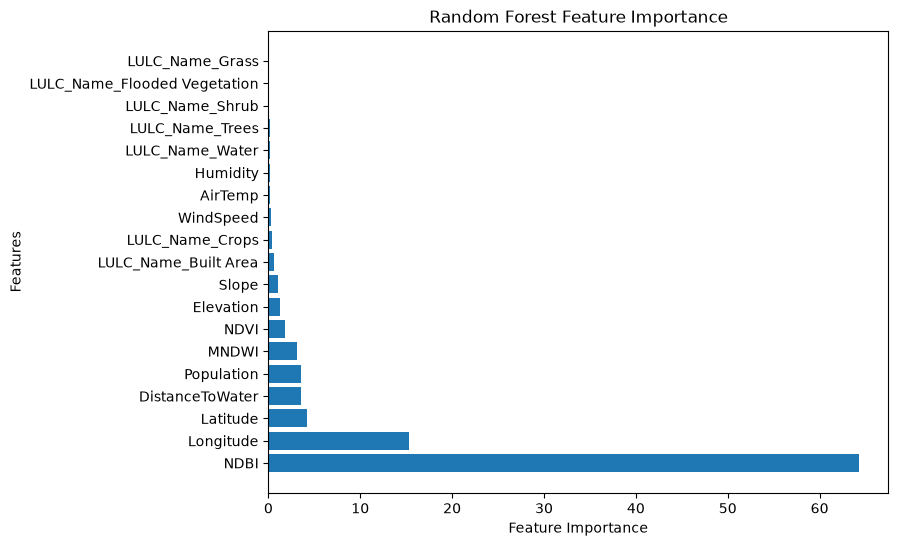

In [13]:
plt.figure(figsize=(8,6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.show()

In [14]:
print(df["AirTemp"].describe())
print(df["AirTemp"].nunique())

count    9989.000000
mean       32.511031
std         0.203881
min        31.983528
25%        32.366906
50%        32.509743
75%        32.641314
max        32.992381
Name: AirTemp, dtype: float64
26


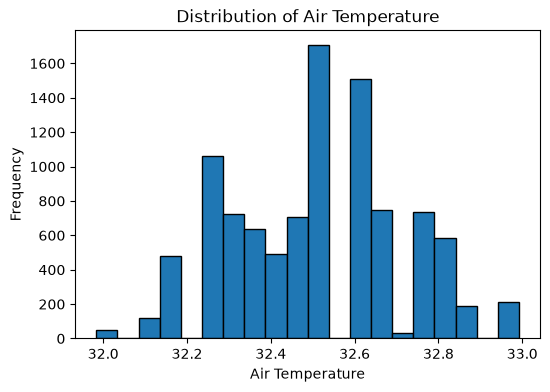

In [15]:
plt.figure(figsize=(6,4))
plt.hist(df["AirTemp"], bins=20, edgecolor="black")
plt.xlabel("Air Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Air Temperature")
plt.show()